In [14]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns 

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import(
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay
)

import joblib
import os

In [5]:
data = pd.read_csv("../data/processed/creditguard_engineered.csv")
print("Data shape:", data.shape)
data.head()

Data shape: (500, 28)


,Customer_ID,Age,Income,Credit_Score,Credit_Utilization,Missed_Payments,Delinquent_Account,Loan_Balance,Debt_to_Income_Ratio,Employment_Status,...,Month_6,On_Time_Count,Late_Count,Missed_Count,Payment_Records_Available,Payment_Issue_Count,Payment_Issue_Rate,Missed_Payment_Rate,On_Time_Rate,Average_Payment_Status
0,CUST0001,56,165580.0,398.0,0.390502,3,0,16310.0,0.317396,emp,...,1,0,4,2,6,6,1.000000,0.333333,0.000000,1.333333
1,CUST0002,69,100999.0,493.0,0.312444,6,1,17401.0,0.196093,self-employed,...,0,2,1,3,6,4,0.666667,0.500000,0.333333,1.166667
2,CUST0003,46,188416.0,500.0,0.359930,0,0,13761.0,0.301655,self-employed,...,1,1,3,2,6,5,0.833333,0.333333,0.166667,1.166667
3,CUST0004,32,101672.0,413.0,0.371400,3,0,88778.0,0.264794,unemployed,...,1,0,4,2,6,6,1.000000,0.333333,0.000000,1.333333
4,CUST0005,60,38524.0,487.0,0.234716,2,0,13316.0,0.510583,self-employed,...,1,1,3,2,6,5,0.833333,0.333333,0.166667,1.166667


In [6]:
selected_features = [
    "Income",
    "Credit_Score",
    "Credit_Utilization",
    "Missed_Payments",
    "Loan_Balance",
    "Debt_to_Income_Ratio",
    "Account_Tenure",
    "On_Time_Count",
    "Late_Count",
    "Missed_Count",
    "Payment_Issue_Count",
    "Payment_Issue_Rate",
    "Missed_Payment_Rate",
    "On_Time_Rate",
    "Average_Payment_Status"
]
X = data[selected_features].copy()
y = data["Delinquent_Account"].copy()
print("Features:",X.shape)
print("Target:",y.shape)

Features: (500, 15)
Target: (500,)


In [7]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training records:", len(X_train))
print("Testing records:", len(X_test))

Training records: 400
Testing records: 100


In [8]:
dummy_model = DummyClassifier(
    strategy = "most_frequent"
)
dummy_model.fit(X_train,y_train)
print("Dummy Classifier trained")

Dummy Classifier trained


In [15]:
logistic_model = Pipeline(
    steps = [
        ("imputer",SimpleImputer(strategy="median")),
        ("scaler",StandardScaler()),
        ("classifier", LogisticRegression(
            class_weight = "balanced",
            max_iter = 1000,
            random_state = 42
        ))
    ]

)
logistic_model.fit(X_train,y_train)
print("Logistic Regression trained")

Logistic Regression trained


In [16]:
random_forest_model = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("classifier", RandomForestClassifier(
            n_estimators=200,
            max_depth=5,
            min_samples_split=5,
            min_samples_leaf=3,
            class_weight="balanced",
            random_state=42
        ))
    ]
)

random_forest_model.fit(X_train, y_train)

print("Random Forest trained!")

Random Forest trained!


In [17]:
def evaluate_model(model, X_test, y_test, model_name):

    predictions = model.predict(X_test)
    probabilities = model.predict_proba(X_test)[:, 1]

    results = {
        "Model": model_name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(
            y_test, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_test, predictions, zero_division=0
        ),
        "F1 Score": f1_score(
            y_test, predictions, zero_division=0
        ),
        "ROC AUC": roc_auc_score(y_test, probabilities),
        "PR AUC": average_precision_score(
            y_test, probabilities
        )
    }

    return results

In [18]:
models = {
    "Dummy Classifier": dummy_model,
    "Logistic Regression": logistic_model,
    "Random Forest": random_forest_model
}

results = []

for name, model in models.items():

    result = evaluate_model(
        model,
        X_test,
        y_test,
        name
    )

    results.append(result)

comparison_df = pd.DataFrame(results)

comparison_df.set_index("Model").round(3)

,Accuracy,Precision,Recall,F1 Score,ROC AUC,PR AUC
Model,,,,,,
Dummy Classifier,0.84,0.000,0.000,0.000,0.500,0.160
Logistic Regression,0.47,0.122,0.375,0.185,0.411,0.200
Random Forest,0.65,0.148,0.250,0.186,0.417,0.142


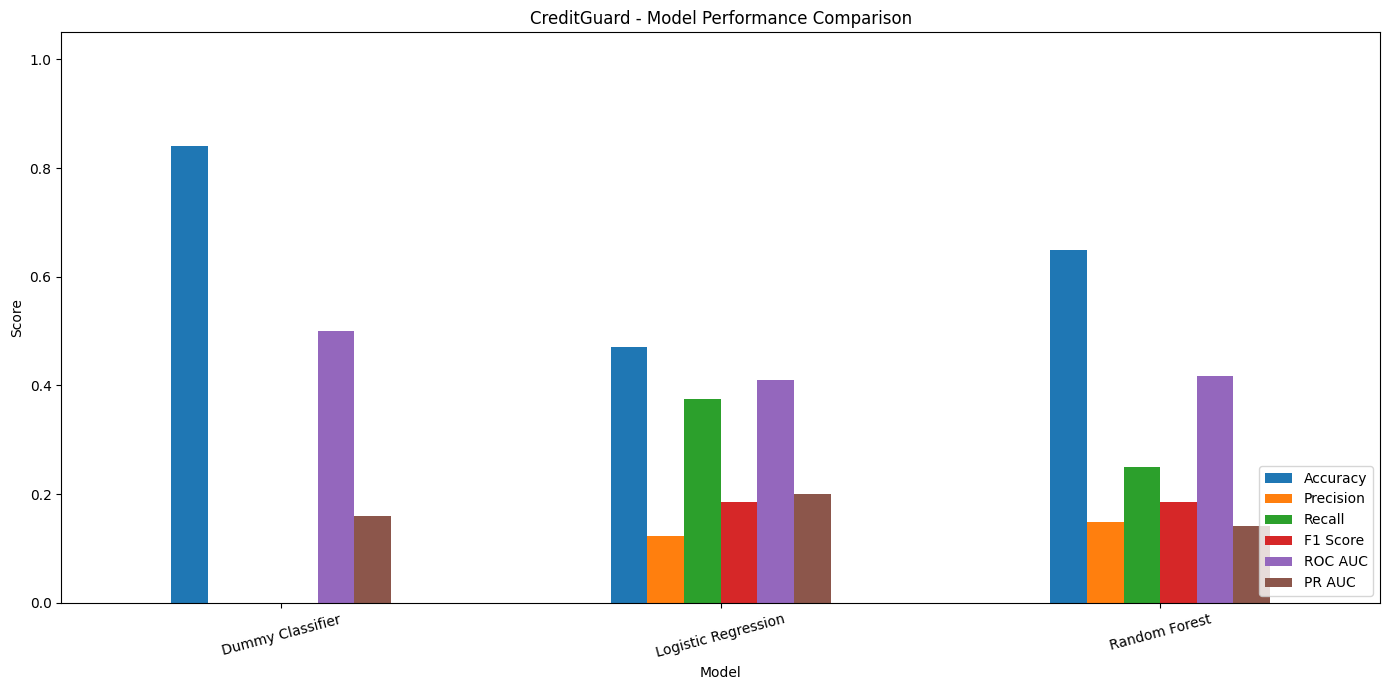

In [19]:
comparison_plot = comparison_df.set_index("Model")[
    ["Accuracy", "Precision", "Recall", "F1 Score", "ROC AUC", "PR AUC"]
]

comparison_plot.plot(
    kind="bar",
    figsize=(14, 7)
)

plt.title("CreditGuard - Model Performance Comparison")
plt.ylabel("Score")
plt.ylim(0, 1.05)
plt.xticks(rotation=15)
plt.legend(loc="lower right")

plt.tight_layout()
plt.show()

In [20]:
logistic_predictions = logistic_model.predict(X_test)

print(
    classification_report(
        y_test,
        logistic_predictions,
        target_names=["Non-D delinquent", "Delinquent"],
        zero_division=0
    )
)

                  precision    recall  f1-score   support

Non-D delinquent       0.80      0.49      0.61        84
      Delinquent       0.12      0.38      0.18        16

        accuracy                           0.47       100
       macro avg       0.46      0.43      0.40       100
    weighted avg       0.69      0.47      0.54       100



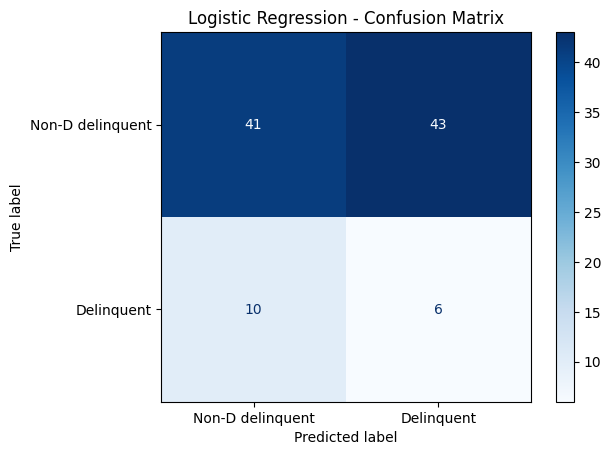

In [21]:
ConfusionMatrixDisplay.from_estimator(
    logistic_model,
    X_test,
    y_test,
    display_labels=["Non-D delinquent", "Delinquent"],
    cmap="Blues"
)

plt.title("Logistic Regression - Confusion Matrix")
plt.show()

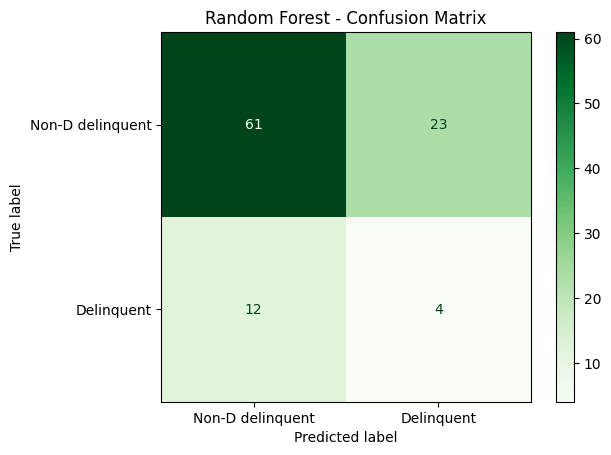

In [22]:
ConfusionMatrixDisplay.from_estimator(
    random_forest_model,
    X_test,
    y_test,
    display_labels=["Non-D delinquent", "Delinquent"],
    cmap="Greens"
)

plt.title("Random Forest - Confusion Matrix")
plt.show()

In [23]:
predicted_probabilities = (
    logistic_model.predict_proba(X_test)[:, 1]
)

predictions_df = pd.DataFrame({
    "Actual": y_test.values,
    "Predicted": logistic_predictions,
    "Delinquency_Probability": predicted_probabilities
})

predictions_df.head(10)

,Actual,Predicted,Delinquency_Probability
0,0,1,0.505142
1,0,1,0.537499
2,0,1,0.533353
3,0,1,0.522045
4,0,0,0.460560
5,0,1,0.517806
6,0,0,0.399380
7,0,0,0.492732
8,0,1,0.597143
9,0,0,0.378727


In [24]:
def assign_risk(probability):

    if probability < 0.30:
        return "Low"

    elif probability < 0.60:
        return "Medium"

    else:
        return "High"


predictions_df["Risk_Category"] = (
    predictions_df["Delinquency_Probability"]
    .apply(assign_risk)
)

predictions_df.head(10)

,Actual,Predicted,Delinquency_Probability,Risk_Category
0,0,1,0.505142,Medium
1,0,1,0.537499,Medium
2,0,1,0.533353,Medium
3,0,1,0.522045,Medium
4,0,0,0.460560,Medium
5,0,1,0.517806,Medium
6,0,0,0.399380,Medium
7,0,0,0.492732,Medium
8,0,1,0.597143,Medium
9,0,0,0.378727,Medium


In [25]:
os.makedirs("../models", exist_ok=True)

In [26]:
joblib.dump(
    logistic_model,
    "../models/logistic_regression.pkl"
)

print("Logistic Regression saved!")

Logistic Regression saved!


In [27]:
joblib.dump(
    random_forest_model,
    "../models/random_forest.pkl"
)

print("Random Forest saved!")

Random Forest saved!


In [28]:
os.makedirs("../reports", exist_ok=True)

comparison_df.to_csv(
    "../reports/model_comparison.csv",
    index=False
)

predictions_df.to_csv(
    "../reports/test_predictions.csv",
    index=False
)

print("Model evaluation results saved!")

Model evaluation results saved!
